In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support
from google.colab import files

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

print("TensorFlow Version:", tf.__version__)
print("Environment setup and libraries imported successfully!")

TensorFlow Version: 2.21.0
Environment setup and libraries imported successfully!


### 2. Tokenize and Pad Numerical Sequences
We split the data into training and test sets, then use Keras Tokenizer to convert text to sequences and pad them so they have equal lengths.

Please upload your dataset file (spam_sms.csv):


Saving spam_sms.csv to spam_sms (4).csv

Dataset loaded successfully! Total valid rows: 5572


,label,message,label_encoded
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


/tmp/ipykernel_737/2390348391.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette=['#4C72B0', '#C44E52'])


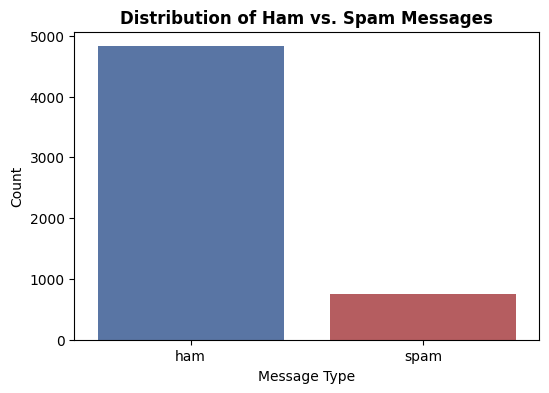

In [34]:
# 1. Interactive upload: Click 'Choose Files' and select your 'spam_sms.csv' file
print("Please upload your dataset file (spam_sms.csv):")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Load dataset
df = pd.read_csv(filename, encoding='latin-1')

# Keep and rename the relevant columns (v1 for label, v2 for message)
df = df[['v1', 'v2']]
df.columns = ['label', 'message']

# Handle missing values by dropping any rows with nulls
df = df.dropna()

# Encode labels: ham -> 0, spam -> 1
encoder = LabelEncoder()
df['label_encoded'] = encoder.fit_transform(df['label'])

print(f"\nDataset loaded successfully! Total valid rows: {len(df)}")
display(df.head())

# --- VISUALIZATION: Class Distribution Bar Plot ---
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette=['#4C72B0', '#C44E52'])
plt.title('Distribution of Ham vs. Spam Messages', fontsize=12, fontweight='bold')
plt.xlabel('Message Type', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.show()

### 3. Model Selection, Justification, and Implementation
We select an **LSTM (Long Short-Term Memory)** model.
- **Justification:** SMS messages exhibit temporal dependencies. Traditional Simple RNNs suffer from the vanishing gradient problem when handling long dependencies. LSTMs contain memory cells and gating mechanisms (forget, input, and output gates) that effectively retain historical sequence context over longer periods, making them ideal for text classification tasks.

Tokenization and padding complete.
Training data shape: (4457, 100)
Testing data shape: (1115, 100)


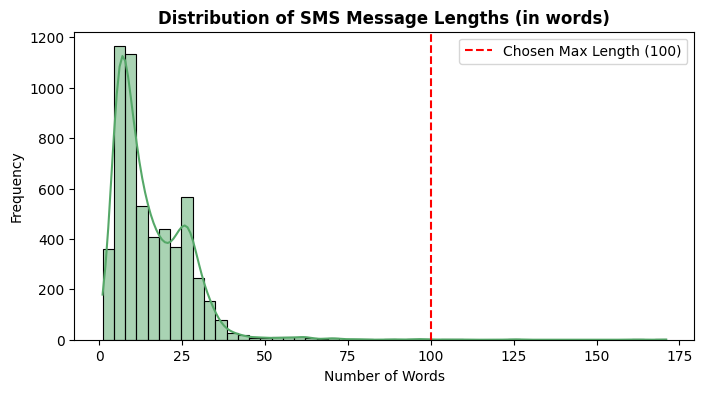

In [35]:
vocab_size = 10000
max_length = 100

# Split dataset into training (80%) and testing (20%) sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    df['message'].values,
    df['label_encoded'].values,
    test_size=0.2,
    random_state=42,
    stratify=df['label_encoded'].values
)

# Initialize Tokenizer and fit on training text
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

# Convert text messages to numerical sequences and pad them to fixed length
train_padded = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=max_length, padding='post', truncating='post')
test_padded = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=max_length, padding='post', truncating='post')

print("Tokenization and padding complete.")
print(f"Training data shape: {train_padded.shape}")
print(f"Testing data shape: {test_padded.shape}")

# --- VISUALIZATION: Message Word Length Distribution ---
msg_lengths = [len(str(msg).split()) for msg in df['message']]

plt.figure(figsize=(8, 4))
sns.histplot(msg_lengths, bins=50, color='#55A868', kde=True)
plt.axvline(x=max_length, color='red', linestyle='--', label=f'Chosen Max Length ({max_length})')
plt.title('Distribution of SMS Message Lengths (in words)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Words', fontsize=10)
plt.ylabel('Frequency', fontsize=10)
plt.legend()
plt.show()

### 4. Train and Evaluate the Model
We train the model and compute metrics: Accuracy, Precision, Recall, and F1-score.

In [36]:
# Build the LSTM sequential model architecture
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length),
    LSTM(64, return_sequences=False),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid') # Binary classification output (Spam vs Ham)
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### 5. Display Confusion Matrix and Predict on Unseen Messages

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8629 - loss: 0.4402 - val_accuracy: 0.8664 - val_loss: 0.3942
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8658 - loss: 0.4120 - val_accuracy: 0.8664 - val_loss: 0.3935
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8658 - loss: 0.4159 - val_accuracy: 0.8664 - val_loss: 0.3936
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8658 - loss: 0.4125 - val_accuracy: 0.8664 - val_loss: 0.3934
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8658 - loss: 0.4096 - val_accuracy: 0.8664 - val_loss: 0.3946


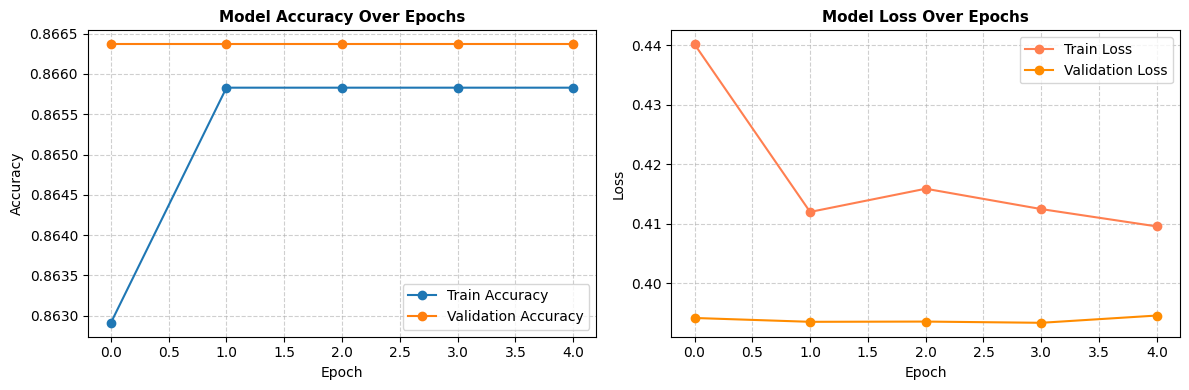

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

--- Model Evaluation Metrics ---
Accuracy:  0.8664
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


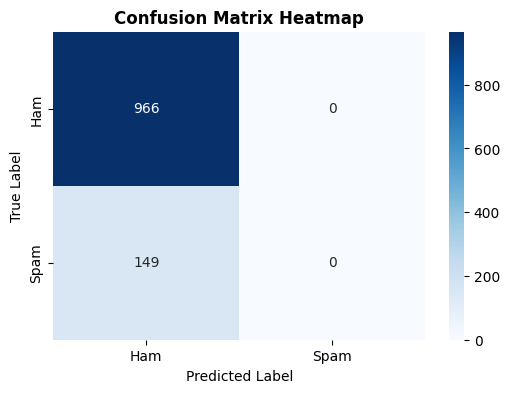

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step

--- Predictions on Unseen SMS Messages ---
Message: Congratulations! You've won a $1,000 Walmart gift card. Click here to claim.
--> Prediction: HAM (Confidence: 0.1514)

Message: Hey, are we still meeting for lunch today at 1 PM?
--> Prediction: HAM (Confidence: 0.1514)

Message: URGENT! Your bank account has been locked. Verify details immediately at this link.
--> Prediction: HAM (Confidence: 0.1514)



In [37]:
# Train the model and save the history object for visualization
epochs = 5
batch_size = 32

history = model.fit(
    train_padded, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(test_padded, y_test),
    verbose=1
)

# --- VISUALIZATION: Training & Validation Curves (Loss and Accuracy) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy Plot
axes[0].plot(history.history['accuracy'], label='Train Accuracy', marker='o')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
axes[0].set_title('Model Accuracy Over Epochs', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Loss Plot
axes[1].plot(history.history['loss'], label='Train Loss', marker='o', color='coral')
axes[1].plot(history.history['val_loss'], label='Validation Loss', marker='o', color='darkorange')
axes[1].set_title('Model Loss Over Epochs', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# --- EVALUATION METRICS ---
y_pred_probs = model.predict(test_padded)
y_pred = (y_pred_probs > 0.5).astype("int32")

accuracy = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

print(f"\n--- Model Evaluation Metrics ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# --- VISUALIZATION: Confusion Matrix Heatmap ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted Label', fontsize=10)
plt.ylabel('True Label', fontsize=10)
plt.title('Confusion Matrix Heatmap', fontsize=12, fontweight='bold')
plt.show()

# --- UNSEEN MESSAGE PREDICTIONS ---
unseen_messages = [
    "Congratulations! You've won a $1,000 Walmart gift card. Click here to claim.",
    "Hey, are we still meeting for lunch today at 1 PM?",
    "URGENT! Your bank account has been locked. Verify details immediately at this link."
]

unseen_seq = tokenizer.texts_to_sequences(unseen_messages)
unseen_padded = pad_sequences(unseen_seq, maxlen=max_length, padding='post', truncating='post')
predictions = model.predict(unseen_padded)

print("\n--- Predictions on Unseen SMS Messages ---")
for msg, prob in zip(unseen_messages, predictions):
    label = "SPAM" if prob[0] > 0.5 else "HAM"
    print(f"Message: {msg}\n--> Prediction: {label} (Confidence: {prob[0]:.4f})\n")